In [1]:
#202431072_ihtia
from pathlib import Path
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

from IPython.display import display, Image

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    cross_val_score,
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
)

SEED = 42

HASIL = Path("hasil")
HASIL.mkdir(exist_ok=True)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "figure.dpi": 120,
})

VERSI = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "scikit-learn": sklearn.__version__,
}


def simpan_gambar(fig, nama_file):
    fig.savefig(
        HASIL / nama_file,
        dpi=180,
        bbox_inches="tight",
        facecolor="white",
    )
    display(Image(filename=str(HASIL / nama_file)))
    plt.close(fig)


display(pd.Series(VERSI, name="Versi"))

python          3.11.7
numpy           1.26.4
pandas           2.1.4
matplotlib       3.8.0
scikit-learn     1.2.2
Name: Versi, dtype: object

In [2]:

#202431072_ihtia
DATA = Path("01_heart_disease.csv")

if not DATA.exists():
    raise FileNotFoundError(
        "Letakkan 01_heart_disease.csv di folder kerja notebook."
    )

DATA_HASH = hashlib.sha256(DATA.read_bytes()).hexdigest()
df = pd.read_csv(DATA)

print("Ukuran data:", df.shape)
print("SHA-256:", DATA_HASH)

display(df.head())


Ukuran data: (918, 12)
SHA-256: 948420b084d8a3a0ca42b8419fce9aee175879e43f8aedf712377899a67aa49b


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
#3
#202431072_ihtia
KOLOM = [
    "Age",
    "Sex",
    "ChestPainType",
    "RestingBP",
    "Cholesterol",
    "FastingBS",
    "RestingECG",
    "MaxHR",
    "ExerciseAngina",
    "Oldpeak",
    "ST_Slope",
    "HeartDisease",
]

assert list(df.columns) == KOLOM, (
    "Struktur kolom berbeda dari dataset eksperimen."
)
assert set(df["HeartDisease"].unique()) == {0, 1}

audit = pd.DataFrame({
    "tipe": df.dtypes.astype(str),
    "kosong": df.isna().sum(),
    "nilai_unik": df.nunique(),
})

duplikat = int(df.duplicated().sum())

print("Baris duplikat:", duplikat)

display(audit)
display(df.describe().round(2))

kategori_awal = pd.DataFrame({
    c: pd.Series(df[c].value_counts().to_dict())
    for c in df.select_dtypes("object").columns
})

display(kategori_awal.fillna(""))

Baris duplikat: 0


,tipe,kosong,nilai_unik
Age,int64,0,50
Sex,object,0,2
ChestPainType,object,0,4
RestingBP,int64,0,67
Cholesterol,int64,0,222
FastingBS,int64,0,2
RestingECG,object,0,3
MaxHR,int64,0,119
ExerciseAngina,object,0,2
Oldpeak,float64,0,53


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.00,918.00,918.00,918.00,918.00,918.00,918.00
mean,53.51,132.40,198.80,0.23,136.81,0.89,0.55
std,9.43,18.51,109.38,0.42,25.46,1.07,0.50
min,28.00,0.00,0.00,0.00,60.00,-2.60,0.00
25%,47.00,120.00,173.25,0.00,120.00,0.00,0.00
50%,54.00,130.00,223.00,0.00,138.00,0.60,1.00
75%,60.00,140.00,267.00,0.00,156.00,1.50,1.00
max,77.00,200.00,603.00,1.00,202.00,6.20,1.00


,Sex,ChestPainType,RestingECG,ExerciseAngina,ST_Slope
ASY,,496.0,,,
ATA,,173.0,,,
Down,,,,,63.0
F,193.0,,,,
Flat,,,,,460.0
LVH,,,188.0,,
M,725.0,,,,
N,,,,547.0,
NAP,,203.0,,,
Normal,,,552.0,,


In [4]:
#4
#202431072_ihtia
bersih = df.copy()

kolom_nol = ["RestingBP", "Cholesterol"]
nol = (bersih[kolom_nol] == 0).sum()

bersih[kolom_nol] = bersih[kolom_nol].replace(0, np.nan)

print("Tidak ada baris dibuang.")
print("Jumlah baris:", len(bersih))

display(pd.DataFrame({
    "nol_ditandai": nol,
    "persen": (nol / len(df) * 100).round(2),
}))

print("Oldpeak negatif dipertahankan.")
print("Pencilan tidak dihapus otomatis.")

Tidak ada baris dibuang.
Jumlah baris: 918


,nol_ditandai,persen
RestingBP,1,0.11
Cholesterol,172,18.74


Oldpeak negatif dipertahankan.
Pencilan tidak dihapus otomatis.


In [5]:
#5
#202431072 IHTIA 
X = bersih.drop(columns="HeartDisease")
y = bersih["HeartDisease"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y,
)

assert set(X_train.index).isdisjoint(X_test.index)
assert "HeartDisease" not in X_train.columns

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

bagian = pd.DataFrame({
    "semua": y.value_counts(),
    "latih": y_train.value_counts(),
    "uji": y_test.value_counts(),
}).sort_index()

bagian.index.name = "HeartDisease"

display(bagian)

print(f"Data latih: {len(X_train)} baris")
print(f"Data uji: {len(X_test)} baris")


,semua,latih,uji
HeartDisease,,,
0,410,328,82
1,508,406,102


Data latih: 734 baris
Data uji: 184 baris


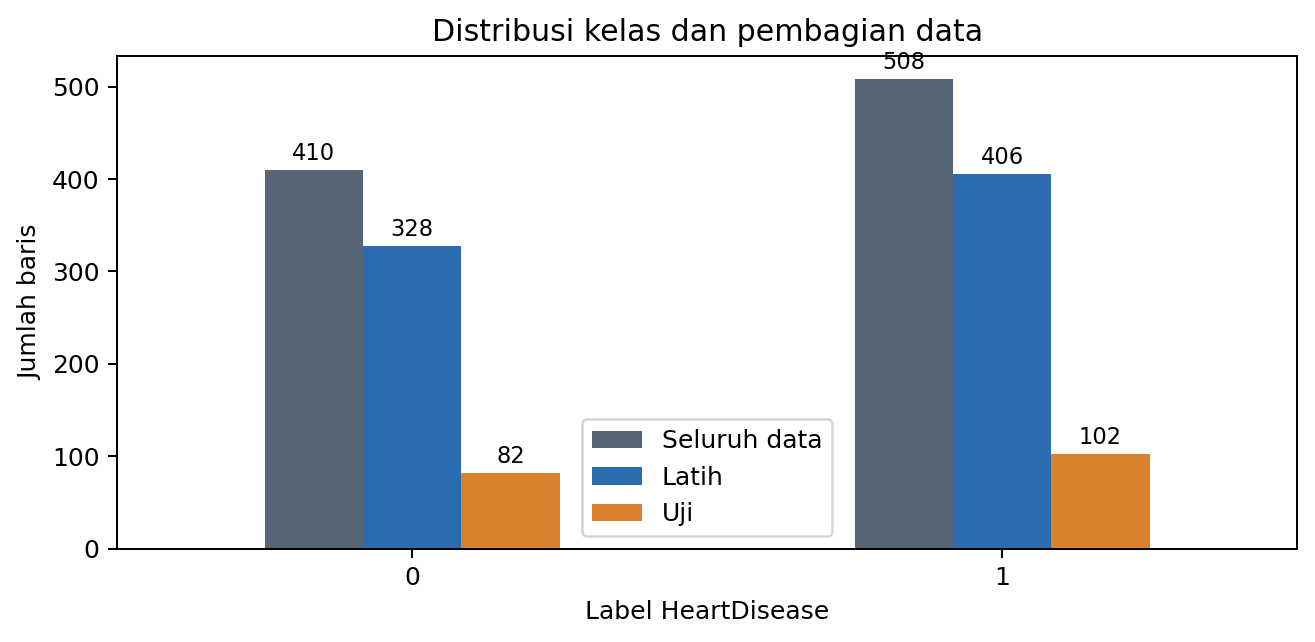

In [6]:
#6
#202431072_ihtia

fig, ax = plt.subplots(figsize=(7.4, 3.8))

bagian.plot.bar(
    ax=ax,
    color=["#566573", "#2b6cb0", "#d9822b"],
    rot=0,
)

ax.set(
    xlabel="Label HeartDisease",
    ylabel="Jumlah baris",
    title="Distribusi kelas dan pembagian data",
)

ax.legend(["Seluruh data", "Latih", "Uji"])

for container in ax.containers:
    ax.bar_label(container, padding=2, fontsize=9)

fig.tight_layout(rect=[0, 0.04, 1, 1])

simpan_gambar(fig, "01_distribusi_target.png")

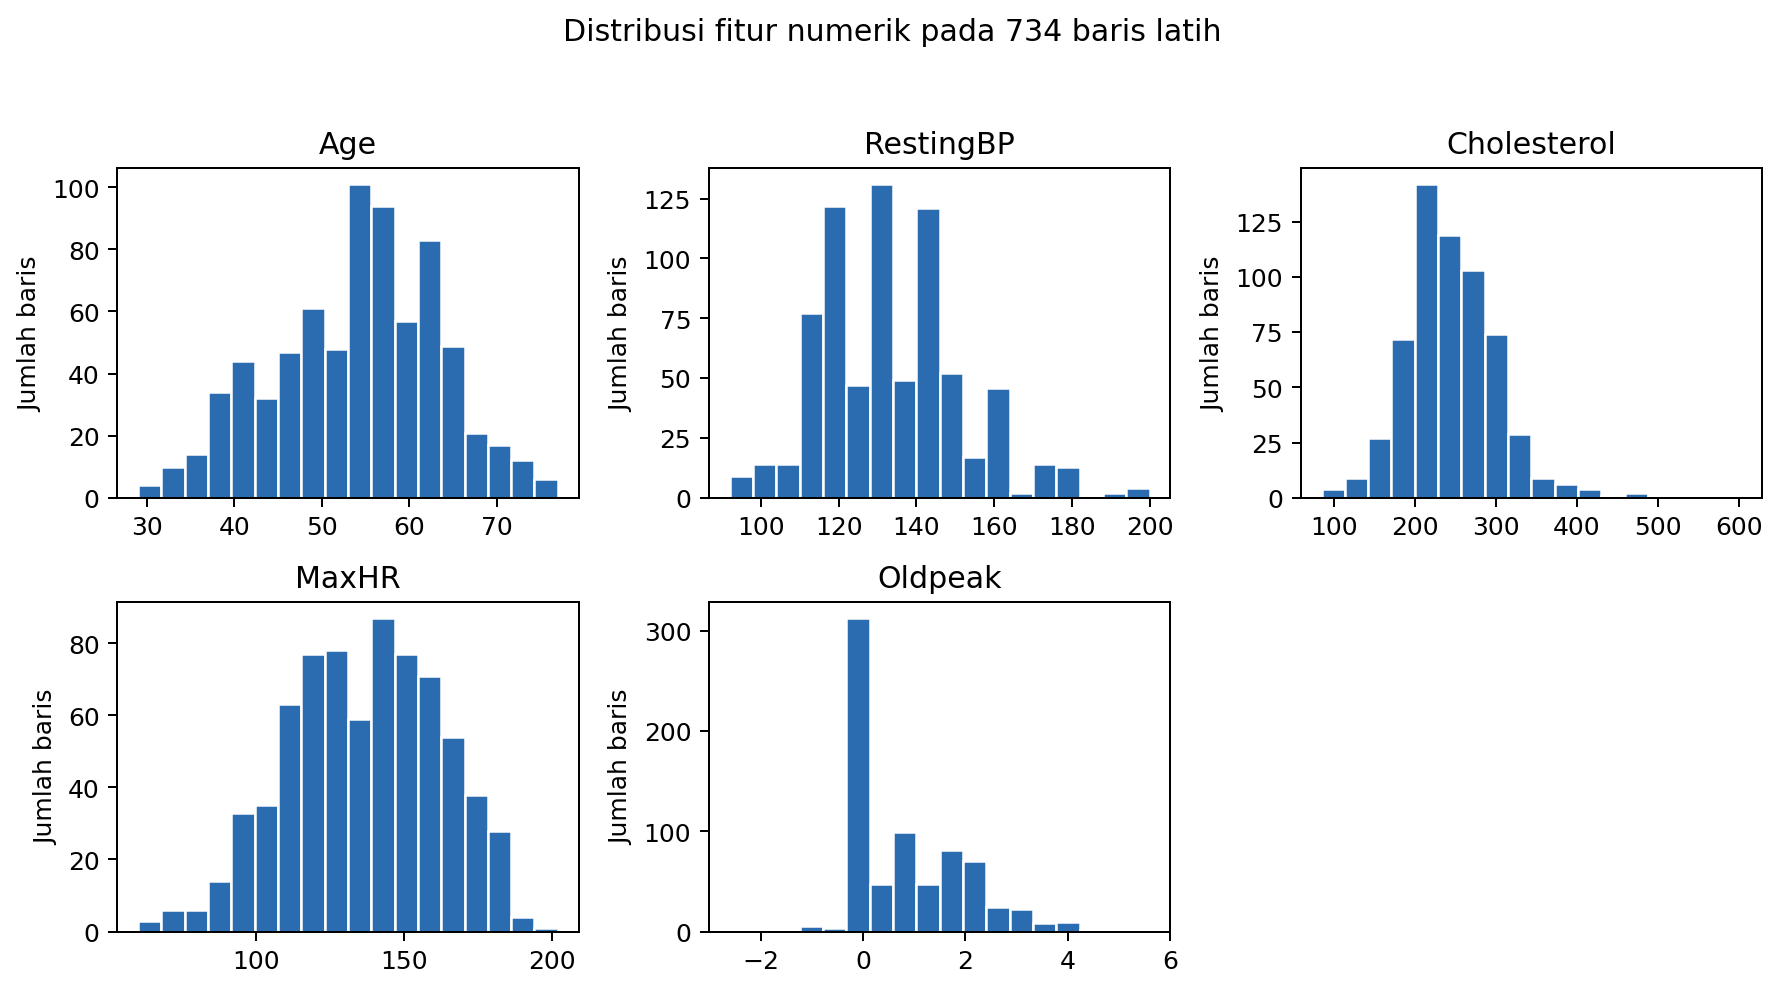

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
count,734.00,734.00,605.00,734.00,734.00
mean,53.85,132.87,246.56,136.38,0.87
std,9.44,18.08,59.66,25.83,1.06
min,29.00,92.00,85.00,60.00,-2.60
25%,47.00,120.00,210.00,119.00,0.00
50%,55.00,130.00,238.00,138.00,0.50
75%,61.00,141.00,277.00,156.00,1.50
max,77.00,200.00,603.00,202.00,5.60


In [7]:
#7
#202431072_ihtia
NUMERIK = [
    "Age",
    "RestingBP",
    "Cholesterol",
    "MaxHR",
    "Oldpeak",
]

KATEGORI = [
    "Sex",
    "ChestPainType",
    "FastingBS",
    "RestingECG",
    "ExerciseAngina",
    "ST_Slope",
]

fig, axes = plt.subplots(2, 3, figsize=(10, 5.8))

for col, ax in zip(NUMERIK, axes.flat):
    ax.hist(
        X_train[col].dropna(),
        bins=18,
        color="#2b6cb0",
        edgecolor="white",
    )
    ax.set(title=col, ylabel="Jumlah baris")

axes.flat[-1].axis("off")

fig.suptitle("Distribusi fitur numerik pada 734 baris latih")
fig.tight_layout(rect=[0, 0.04, 1, 0.95])

simpan_gambar(fig, "02_histogram_latih.png")

display(X_train[NUMERIK].describe().round(2))

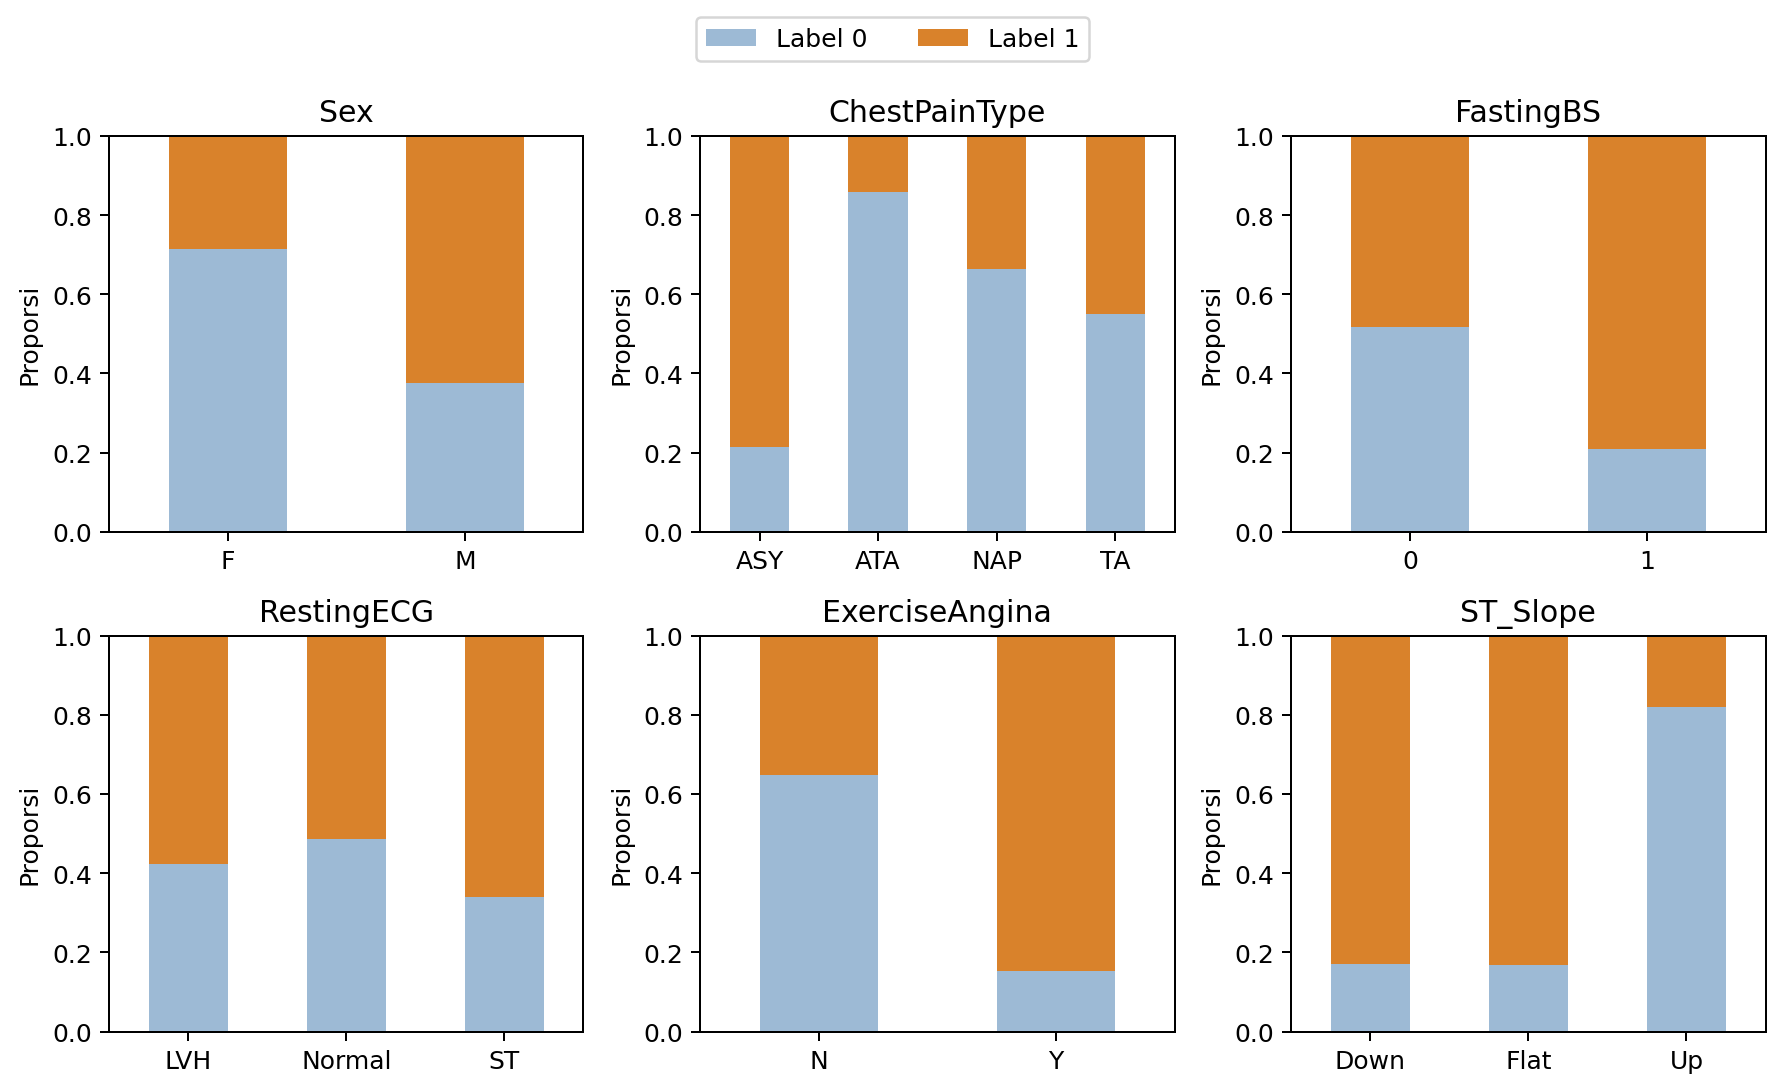

HeartDisease,0,1
ST_Slope,,
Down,8,39
Flat,63,311
Up,257,56


In [8]:
#8
#202431072_ihtia
eda_train = X_train.assign(HeartDisease=y_train)

fig, axes = plt.subplots(2, 3, figsize=(10, 6.2))
proporsi_kategori = {}

for col, ax in zip(KATEGORI, axes.flat):
    tabel = pd.crosstab(
        eda_train[col],
        y_train,
        normalize="index",
    ).reindex(
        columns=[0, 1],
        fill_value=0,
    )

    proporsi_kategori[col] = tabel

    tabel.plot.bar(
        stacked=True,
        ax=ax,
        color=["#9dbad5", "#d9822b"],
        rot=0,
        legend=False,
    )

    ax.set(
        title=col,
        xlabel="",
        ylabel="Proporsi",
        ylim=(0, 1),
    )

handles, labels = axes.flat[0].get_legend_handles_labels()

fig.legend(
    handles,
    ["Label 0", "Label 1"],
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 1.02),
)

fig.tight_layout(rect=[0, 0.04, 1, 0.96])

simpan_gambar(fig, "03_kategori_latih.png")

display(pd.crosstab(eda_train["ST_Slope"], y_train))

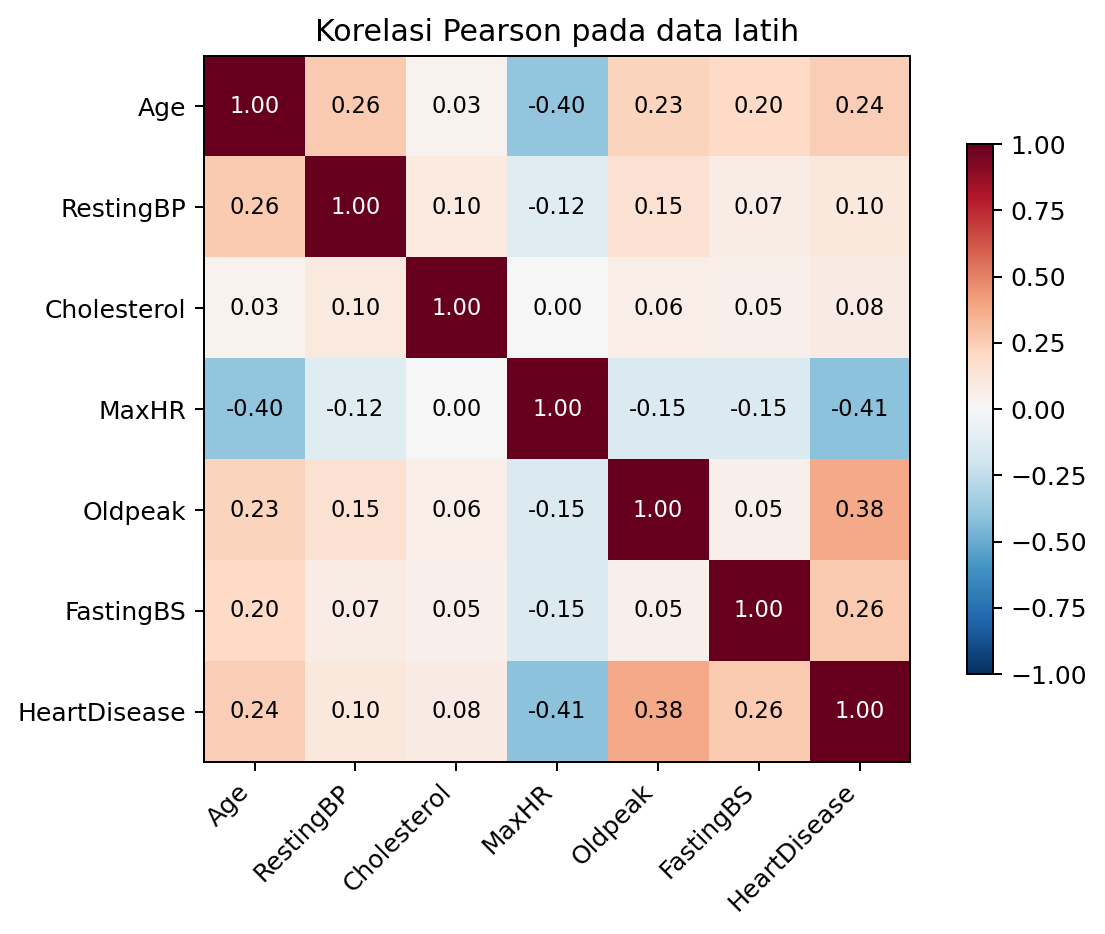

In [9]:
#202431072_ihtia
kol_corr = NUMERIK + ["FastingBS", "HeartDisease"]
korelasi = eda_train[kol_corr].corr()
fig, ax = plt.subplots(figsize=(7.3, 5.5))
im = ax.imshow(
    korelasi,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
)

ax.set_xticks(
    range(len(kol_corr)),
    kol_corr,
    rotation=45,
    ha="right",
)

ax.set_yticks(
    range(len(kol_corr)),
    kol_corr,
)
for i in range(len(kol_corr)):
    for j in range(len(kol_corr)):
        nilai = korelasi.iloc[i, j]
        ax.text(
            j,
            i,
            f"{nilai:.2f}",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if abs(nilai) > 0.65 else "black",
        )
ax.set_title("Korelasi Pearson pada data latih")

fig.colorbar(im, ax=ax, shrink=0.75)
fig.tight_layout(rect=[0, 0.04, 1, 1])

simpan_gambar(fig, "04_korelasi_latih.png")

In [10]:
#202431072_ihtia
def buat_pipeline(model, skala=False):
    langkah_num = [
        ("imputer", SimpleImputer(strategy="median")),
    ]
    if skala:
        langkah_num.append(
            ("scaler", StandardScaler())
        )
    numerik_pipe = Pipeline(langkah_num)
    kategori_pipe = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent"),
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
        ),
    ])
    prep = ColumnTransformer([
        ("num", numerik_pipe, NUMERIK),
        ("cat", kategori_pipe, KATEGORI),
    ])

    return Pipeline([
        ("prep", prep),
        ("model", model),
    ])
print("Numerik:", NUMERIK)
print("Kategori termasuk FastingBS biner:", KATEGORI)

print(
    "Median, modus, kategori, dan skala dipelajari ulang "
    "hanya dari bagian latih setiap fold."
)

print(
    "GaussianNB pada one-hot adalah pendekatan; "
    "fitur biner tidak berdistribusi Gaussian."
)

Numerik: ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
Kategori termasuk FastingBS biner: ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Median, modus, kategori, dan skala dipelajari ulang hanya dari bagian latih setiap fold.
GaussianNB pada one-hot adalah pendekatan; fitur biner tidak berdistribusi Gaussian.


In [11]:
#202431072_ihtia
# SEL 11  Baseline kelas mayoritas
baseline = DummyClassifier(strategy="most_frequent")
baseline_cv = cross_val_score(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
)
baseline.fit(X_train, y_train)

print("Kelas mayoritas latih:", y_train.mode().iloc[0])
print("Akurasi CV baseline:", np.round(baseline_cv, 4))
print(
    f"Rata-rata {baseline_cv.mean():.4f}; "
    f"simpangan baku {baseline_cv.std():.4f}"
)



Kelas mayoritas latih: 1
Akurasi CV baseline: [0.5578 0.551  0.551  0.551  0.5548]
Rata-rata 0.5531; simpangan baku 0.0028
Parameter terpilih: {'model__var_smoothing': 0.01}
Akurasi CV terbaik: 0.8501


In [12]:
# 202431072_ihtia
# Pelatihan dan tuning Naive Bayes

nb_grid = {
    "model__var_smoothing": np.logspace(-11, -1, 11),
}

nb_search = GridSearchCV(
    buat_pipeline(GaussianNB(), skala=True),
    nb_grid,
    scoring="accuracy",
    cv=cv,
    refit=True,
    n_jobs=1,
    error_score="raise",
    return_train_score=True,
)

nb_search.fit(X_train, y_train)

print("Parameter terpilih:", nb_search.best_params_)
print(f"Akurasi CV terbaik: {nb_search.best_score_:.4f}")

Parameter terpilih: {'model__var_smoothing': 0.01}
Akurasi CV terbaik: 0.8501


In [13]:
# 202431072_ihtia
# SEL 13 - Pelatihan dan tuning Decision Tree

dt_grid = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [2, 3, 4, 5, 7, None],
    "model__min_samples_leaf": [1, 5, 10, 20],
    "model__ccp_alpha": [0.0, 0.005],
}

dt_search = GridSearchCV(
    buat_pipeline(
        DecisionTreeClassifier(random_state=SEED)
    ),
    dt_grid,
    scoring="accuracy",
    cv=cv,
    refit=True,
    n_jobs=1,
    error_score="raise",
    return_train_score=True,
)

dt_search.fit(X_train, y_train)

print("Parameter terpilih:", dt_search.best_params_)
print(f"Akurasi CV terbaik: {dt_search.best_score_:.4f}")


Parameter terpilih: {'model__ccp_alpha': 0.0, 'model__criterion': 'gini', 'model__max_depth': 4, 'model__min_samples_leaf': 10}
Akurasi CV terbaik: 0.8406


In [14]:
# 202431072_ihtia
# SEL 14 - Perbandingan validasi silang dan pemilihan model

pencarian = {
    "Naive Bayes": nb_search,
    "Decision Tree": dt_search,
}

baris_cv = [{
    "model": "Baseline",
    "cv_mean": baseline_cv.mean(),
    "cv_std": baseline_cv.std(),
}]

for nama, cari in pencarian.items():
    baris_cv.append({
        "model": nama,
        "cv_mean": cari.best_score_,
        "cv_std": cari.cv_results_["std_test_score"][
            cari.best_index_
        ],
    })

cv_tabel = pd.DataFrame(
    baris_cv
).set_index("model")

PILIHAN_CV = max(
    pencarian,
    key=lambda nama: pencarian[nama].best_score_,
)

display(cv_tabel.round(4))

print("Model pilihan berdasarkan CV:", PILIHAN_CV)

for nama, cari in pencarian.items():
    top = (
        pd.DataFrame(cari.cv_results_)
        .sort_values([
            "rank_test_score",
            "std_test_score",
        ])
        .head(5)
    )

    print(nama, "- lima kandidat teratas")

    display(
        top[
            [
                "params",
                "mean_test_score",
                "std_test_score",
            ]
        ].reset_index(drop=True)
    )


,cv_mean,cv_std
model,,
Baseline,0.5531,0.0028
Naive Bayes,0.8501,0.0227
Decision Tree,0.8406,0.0413


Model pilihan berdasarkan CV: Naive Bayes
Naive Bayes - lima kandidat teratas


,params,mean_test_score,std_test_score
0,{'model__var_smoothing': 0.01},0.850144,0.022711
1,{'model__var_smoothing': 1e-11},0.846053,0.018008
2,{'model__var_smoothing': 1e-10},0.846053,0.018008
3,{'model__var_smoothing': 1e-09},0.846053,0.018008
4,{'model__var_smoothing': 1e-08},0.846053,0.018008


Decision Tree - lima kandidat teratas


,params,mean_test_score,std_test_score
0,"{'model__ccp_alpha': 0.0, 'model__criterion': ...",0.840621,0.041326
1,"{'model__ccp_alpha': 0.0, 'model__criterion': ...",0.840621,0.041326
2,"{'model__ccp_alpha': 0.005, 'model__criterion'...",0.839260,0.042643
3,"{'model__ccp_alpha': 0.0, 'model__criterion': ...",0.839241,0.034824
4,"{'model__ccp_alpha': 0.0, 'model__criterion': ...",0.839241,0.034824


In [15]:
#202431072_ihtia
# SEL 15 - Evaluasi akhir pada data uji

def wilson(benar, n, z=1.959963984540054):
    p = benar / n
    penyebut = 1 + z * z / n

    tengah = (
        p + z * z / (2 * n)
    ) / penyebut

    lebar = (
        z
        * np.sqrt(
            p * (1 - p) / n
            + z * z / (4 * n * n)
        )
        / penyebut
    )

    return tengah - lebar, tengah + lebar


model_final = {
    "Baseline": baseline,
    "Naive Bayes": nb_search.best_estimator_,
    "Decision Tree": dt_search.best_estimator_,
}

prediksi = {}
probabilitas = {}
baris_hasil = []

for nama, model in model_final.items():
    pred = model.predict(X_test)

    indeks_positif = list(model.classes_).index(1)

    proba = model.predict_proba(X_test)[
        :, indeks_positif
    ]

    prediksi[nama] = pred
    probabilitas[nama] = proba

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        pred,
        labels=[0, 1],
    ).ravel()

    lo, hi = wilson(
        int(tn + tp),
        len(y_test),
    )

    baris_hasil.append({
        "model": nama,
        "accuracy": accuracy_score(y_test, pred),
        "balanced_accuracy": balanced_accuracy_score(
            y_test, pred
        ),
        "precision": precision_score(
            y_test,
            pred,
            zero_division=0,
        ),
        "recall": recall_score(y_test, pred),
        "specificity": tn / (tn + fp),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "accuracy_ci_low": lo,
        "accuracy_ci_high": hi,
        "train_accuracy": accuracy_score(
            y_train,
            model.predict(X_train),
        ),
    })

metrik = pd.DataFrame(
    baris_hasil
).set_index("model")

display(metrik.round(4))

print(
    "Pilihan model tetap mengikuti CV:",
    PILIHAN_CV,
)


,accuracy,balanced_accuracy,precision,recall,specificity,f1,roc_auc,tn,fp,fn,tp,accuracy_ci_low,accuracy_ci_high,train_accuracy
model,,,,,,,,,,,,,,
Baseline,0.5543,0.5000,0.5543,1.0000,0.0000,0.7133,0.5000,0,82,0,102,0.4821,0.6243,0.5531
Naive Bayes,0.8641,0.8619,0.8738,0.8824,0.8415,0.8780,0.9212,69,13,12,90,0.8071,0.9062,0.8542
Decision Tree,0.7935,0.7922,0.8200,0.8039,0.7805,0.8119,0.8478,64,18,20,82,0.7293,0.8457,0.8624


Pilihan model tetap mengikuti CV: Naive Bayes


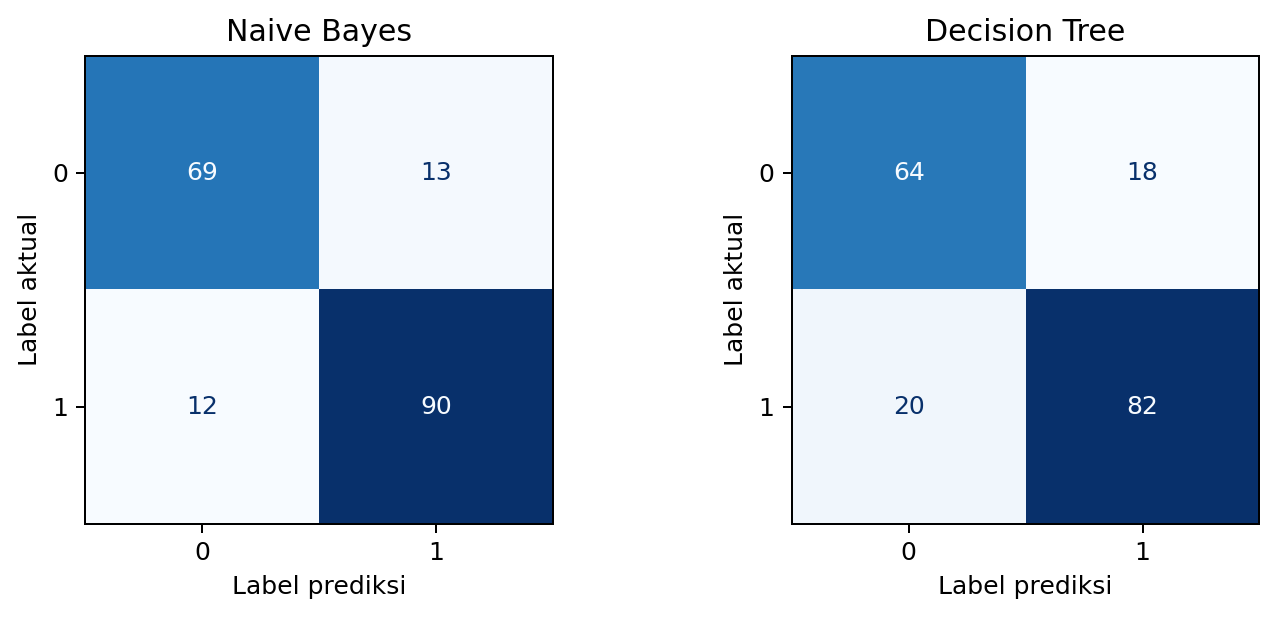

In [16]:
# 202431072_ihtia
# SEL 16 - Confusion matrix kedua algoritma

fig, axes = plt.subplots(
    1,
    2,
    figsize=(8, 3.7),
)

for nama, ax in zip(pencarian, axes):
    cm = confusion_matrix(
        y_test,
        prediksi[nama],
        labels=[0, 1],
    )

    ConfusionMatrixDisplay(
        cm,
        display_labels=[0, 1],
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
    )

    ax.set_title(nama)
    ax.set_xlabel("Label prediksi")
    ax.set_ylabel("Label aktual")

fig.tight_layout(rect=[0, 0.06, 1, 1])

simpan_gambar(fig, "05_confusion_matrix.png")

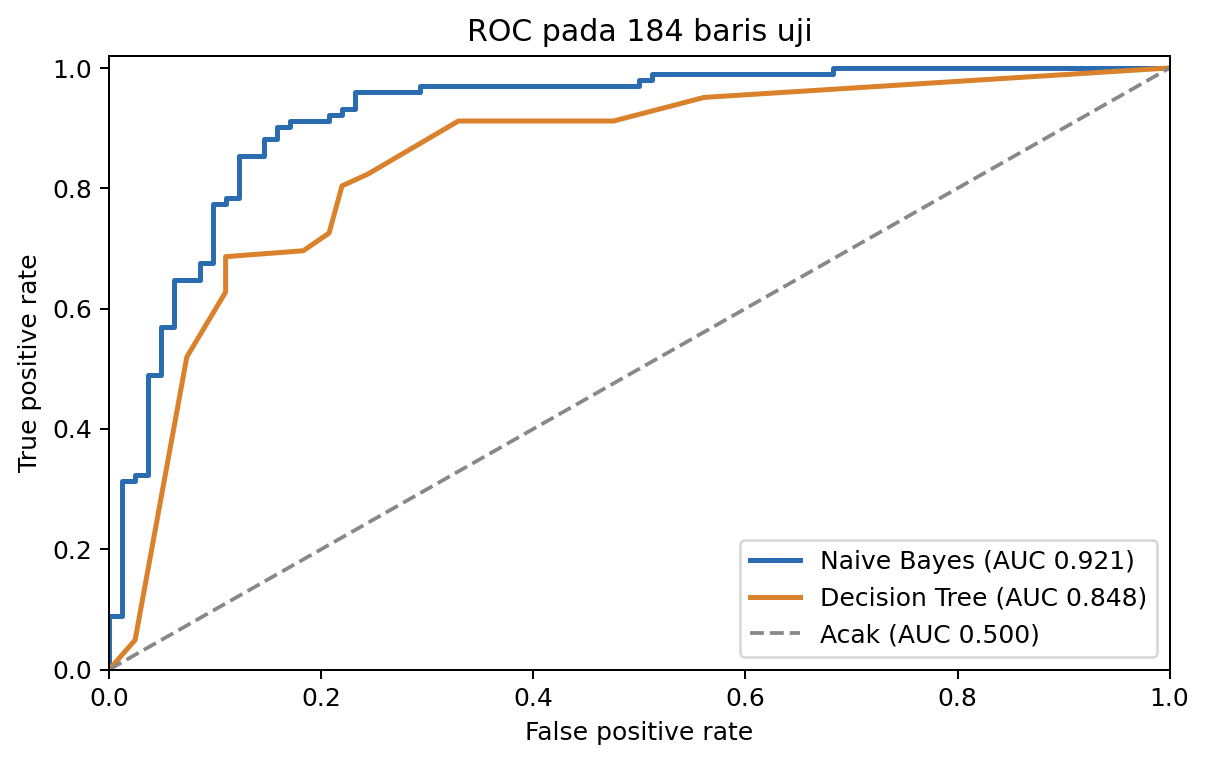

In [17]:
# 202431072_ihtia
# SEL 17 - Kurva ROC dan AUC

fig, ax = plt.subplots(figsize=(6.8, 4.5))

for nama, warna in zip(
    pencarian,
    ["#2b6cb0", "#d9822b"],
):
    fpr, tpr, _ = roc_curve(
        y_test,
        probabilitas[nama],
    )

    auc = metrik.loc[nama, "roc_auc"]

    ax.plot(
        fpr,
        tpr,
        label=f"{nama} (AUC {auc:.3f})",
        color=warna,
        lw=2,
    )

ax.plot(
    [0, 1],
    [0, 1],
    "--",
    color="#888888",
    label="Acak (AUC 0.500)",
)

ax.set(
    xlabel="False positive rate",
    ylabel="True positive rate",
    title="ROC pada 184 baris uji",
    xlim=(0, 1),
    ylim=(0, 1.02),
)

ax.legend(loc="lower right")

fig.tight_layout(rect=[0, 0.04, 1, 1])

simpan_gambar(fig, "06_roc.png")




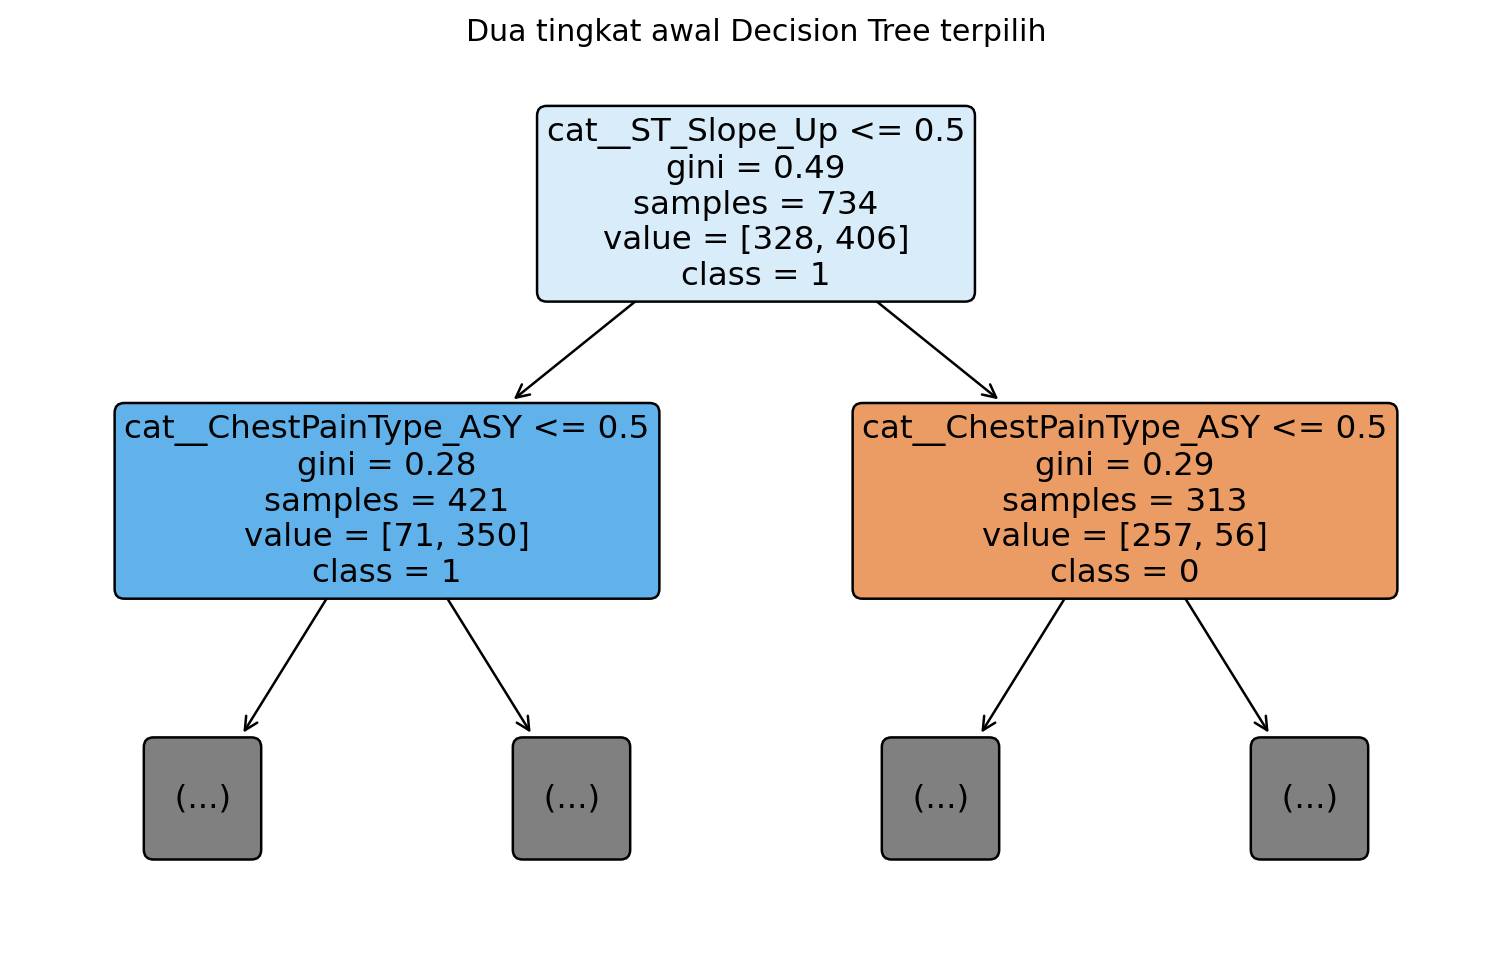

Kedalaman pohon: 4 | Jumlah daun: 16
Aturan lengkap tersimpan di hasil/aturan_decision_tree.txt


In [18]:
# 202431072 ihtia
# SEL 18 - Interpretasi pohon keputusan

dt_best = dt_search.best_estimator_
pohon = dt_best.named_steps["model"]

nama_fitur = (
    dt_best.named_steps["prep"]
    .get_feature_names_out()
)

fig, ax = plt.subplots(figsize=(8.5, 6.0))

plot_tree(
    pohon,
    feature_names=nama_fitur,
    class_names=["0", "1"],
    max_depth=1,
    filled=True,
    rounded=True,
    precision=2,
    fontsize=13,
    ax=ax,
)

ax.set_title(
    "Dua tingkat awal Decision Tree terpilih"
)

fig.tight_layout(rect=[0, 0.05, 1, 0.96])

simpan_gambar(fig, "07_pohon_keputusan.png")

aturan = export_text(
    pohon,
    feature_names=list(nama_fitur),
    decimals=3,
)

(HASIL / "aturan_decision_tree.txt").write_text(
    aturan,
    encoding="utf-8",
)

print(
    "Kedalaman pohon:",
    pohon.get_depth(),
    "| Jumlah daun:",
    pohon.get_n_leaves(),
)

print(
    "Aturan lengkap tersimpan di "
    "hasil/aturan_decision_tree.txt"
)


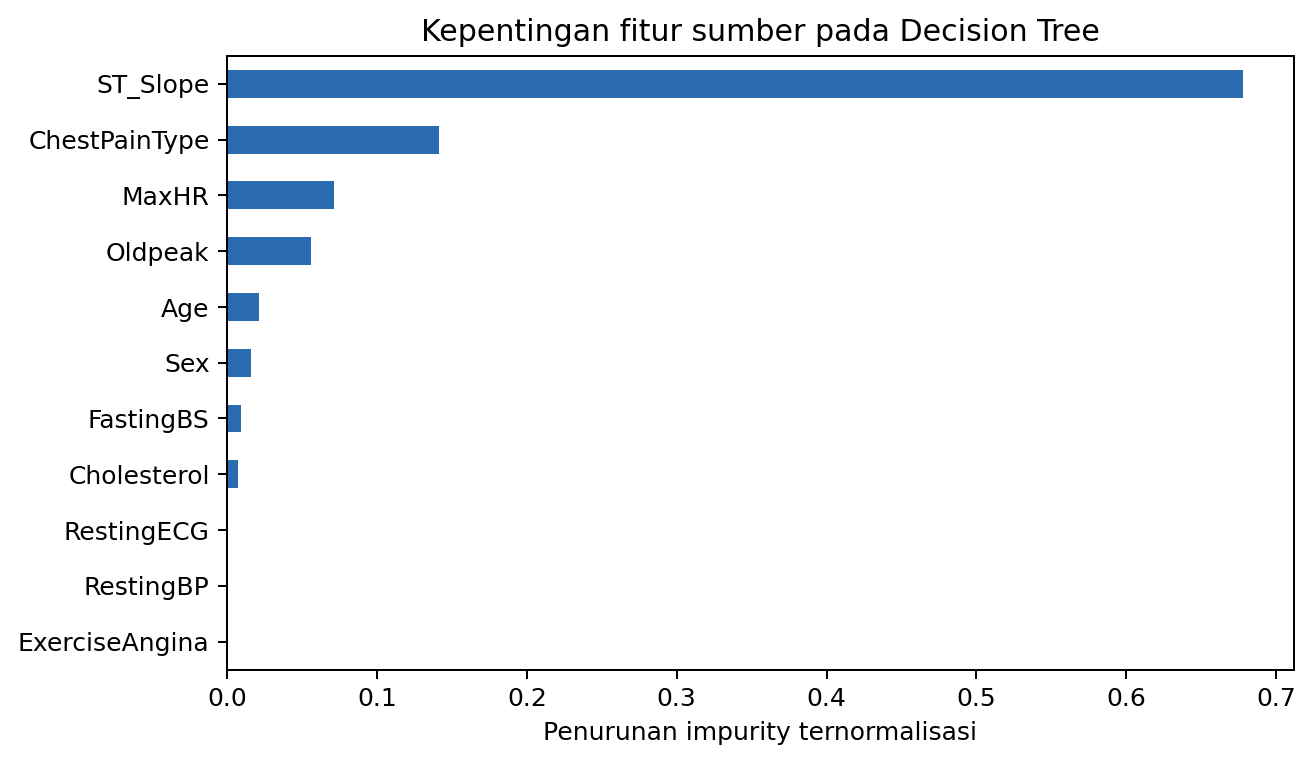

,importance
ST_Slope,0.6778
ChestPainType,0.1412
MaxHR,0.0714
Oldpeak,0.0558
Age,0.0216
Sex,0.0159
FastingBS,0.0090
Cholesterol,0.0072
ExerciseAngina,0.0000
RestingBP,0.0000


In [19]:
# 202431072_ihtia
# SEL 19 - Kepentingan fitur Decision Tree

def fitur_asal(nama):
    if nama.startswith("num__"):
        return nama.removeprefix("num__")

    sisa = nama.removeprefix("cat__")

    return next(
        c
        for c in KATEGORI
        if sisa.startswith(c + "_")
    )


importance_detail = pd.Series(
    pohon.feature_importances_,
    index=nama_fitur,
)

importance = (
    importance_detail
    .groupby([
        fitur_asal(n)
        for n in nama_fitur
    ])
    .sum()
    .sort_values(ascending=False)
)

assert np.isclose(importance.sum(), 1.0)

fig, ax = plt.subplots(figsize=(7.4, 4.5))

importance.sort_values().plot.barh(
    ax=ax,
    color="#2b6cb0",
)

ax.set(
    xlabel="Penurunan impurity ternormalisasi",
    ylabel="",
    title="Kepentingan fitur sumber pada Decision Tree",
)

fig.tight_layout(rect=[0, 0.04, 1, 1])

simpan_gambar(fig, "08_kepentingan_fitur.png")

display(
    importance.to_frame(
        "importance"
    ).round(4)
)

In [20]:
#202431072_ihtia
# SEL 20 - Contoh hasil prediksi
contoh = pd.DataFrame({
    "baris_csv": X_test.index + 2,
    "aktual": y_test.to_numpy(),
    "pred_nb": prediksi["Naive Bayes"],
    "skor_nb_1": probabilitas["Naive Bayes"],
    "pred_dt": prediksi["Decision Tree"],
    "skor_dt_1": probabilitas["Decision Tree"],
})

display(contoh.head(10).round(4))

print(
    "Skor kelas 1 belum dikalibrasi. "
    "Contoh berasal dari data uji yang telah disisihkan."
)



,baris_csv,aktual,pred_nb,skor_nb_1,pred_dt,skor_dt_1
0,358,1,1,1.0000,1,0.9595
1,765,1,0,0.0129,0,0.0000
2,819,1,1,1.0000,1,0.9595
3,737,1,0,0.4063,0,0.4151
4,894,0,0,0.0001,1,0.7143
5,797,0,1,0.9997,0,0.4151
6,236,0,0,0.0000,0,0.0000
7,385,1,0,0.0065,1,0.6364
8,644,0,0,0.0000,0,0.0000
9,456,1,1,1.0000,1,0.9595


Skor kelas 1 belum dikalibrasi. Contoh berasal dari data uji yang telah disisihkan.


In [21]:
# %%
# SEL 21 - Menyimpan hasil dan catatan replikasi

metrik.to_csv(
    HASIL / "metrik_evaluasi.csv"
)

cv_tabel.to_csv(
    HASIL / "ringkasan_cv.csv"
)

contoh.to_csv(
    HASIL / "prediksi_data_uji.csv",
    index=False,
)

importance.to_csv(
    HASIL / "kepentingan_fitur.csv",
    header=["importance"],
)

pembagian_data = pd.DataFrame({
    "baris_csv": bersih.index + 2,
    "bagian": [
        "latih" if i in X_train.index else "uji"
        for i in bersih.index
    ],
})

pembagian_data.to_csv(
    HASIL / "pembagian_data.csv",
    index=False,
)

for nama, cari in pencarian.items():
    nama_file = (
        "cv_"
        + nama.lower().replace(" ", "_")
        + ".csv"
    )

    pd.DataFrame(
        cari.cv_results_
    ).to_csv(
        HASIL / nama_file,
        index=False,
    )

imputer = (
    dt_best.named_steps["prep"]
    .named_transformers_["num"]
    .named_steps["imputer"]
)

median_latih = dict(
    zip(NUMERIK, imputer.statistics_)
)

ringkasan = {
    "file": DATA.name,
    "sha256": DATA_HASH,
    "versi": VERSI,
    "seed": SEED,
    "jumlah_data": len(df),
    "jumlah_latih": len(X_train),
    "jumlah_uji": len(X_test),
    "distribusi_kelas": bagian.to_dict(),
    "nol_ditandai": nol.to_dict(),
    "median_latih": median_latih,
    "pilihan_cv": PILIHAN_CV,
    "parameter": {
        n: c.best_params_
        for n, c in pencarian.items()
    },
    "cv": cv_tabel.to_dict(
        orient="index"
    ),
    "metrik": metrik.to_dict(
        orient="index"
    ),
    "tree_depth": pohon.get_depth(),
    "tree_leaves": pohon.get_n_leaves(),
    "importance": importance.to_dict(),
    "korelasi_target_latih": (
        korelasi["HeartDisease"]
        .drop("HeartDisease")
        .to_dict()
    ),
}

(HASIL / "ringkasan.json").write_text(
    json.dumps(
        ringkasan,
        indent=2,
        default=float,
    ),
    encoding="utf-8",
)

display(
    pd.Series(
        median_latih,
        name="Median dari data latih",
    )
)

print("Hasil tersimpan di", HASIL)


Age             55.0
RestingBP      130.0
Cholesterol    238.0
MaxHR          138.0
Oldpeak          0.5
Name: Median dari data latih, dtype: float64

Hasil tersimpan di hasil


In [22]:
# 202431072 ihtia
# SEL 22 - Kesimpulan eksperimen

print(
    "Model pilihan berdasarkan CV:",
    PILIHAN_CV,
)

for nama in pencarian:
    r = metrik.loc[nama]

    print(
        f"{nama}: "
        f"akurasi {r['accuracy']:.2%}, "
        f"recall {r['recall']:.2%}, "
        f"F1 {r['f1']:.4f}, "
        f"AUC {r['roc_auc']:.4f}; "
        f"FN {int(r['fn'])}."
    )

print(
    "Keterbatasan: satu split internal, "
    "asal populasi dan ID pasien tidak tersedia,"
)

print(
    "banyak kolesterol bernilai nol, "
    "asumsi Gaussian untuk fitur one-hot "
    "hanya pendekatan,"
)

print(
    "serta belum ada kalibrasi probabilitas "
    "atau validasi eksternal."
)

print(
    "Hasil berlaku pada eksperimen dataset ini "
    "dan tidak membuktikan kesiapan klinis."
)

Model pilihan berdasarkan CV: Naive Bayes
Naive Bayes: akurasi 86.41%, recall 88.24%, F1 0.8780, AUC 0.9212; FN 12.
Decision Tree: akurasi 79.35%, recall 80.39%, F1 0.8119, AUC 0.8478; FN 20.
Keterbatasan: satu split internal, asal populasi dan ID pasien tidak tersedia,
banyak kolesterol bernilai nol, asumsi Gaussian untuk fitur one-hot hanya pendekatan,
serta belum ada kalibrasi probabilitas atau validasi eksternal.
Hasil berlaku pada eksperimen dataset ini dan tidak membuktikan kesiapan klinis.
